# Ćwiczenie 5: Przekształcenia lokalne w analizie obrazów medycznych
## Część 2: Szum diagnostyczny i kwantyfikacja jakości (SNR)

### 1. Rodzaje szumu w obrazowaniu medycznym
Aby skutecznie filtrować obraz, fizyk medyczny musi wiedzieć, z jakim rodzajem zakłóceń ma do czynienia:
*   **Szum Gaussa:** Powstaje głównie w elektronice odczytowej i termicznych zjawiskach w układach (np. cewki MRI). Zmiany jasności pikseli podlegają rozkładowi normalnemu.
*   **Szum Kwantowy (Poissona):** Fundamentalny problem radiologii (RTG, CT, PET). Wynika z faktu, że promieniowanie ma naturę korpuskularną (fotony). Jeśli pacjent jest otyły, bardzo mało fotonów dociera do detektora. Powstaje statystyczna fluktuacja (szum typu "mottle").
*   **Szum Impulsowy (Pieprz i Sól):** Występuje rzadko w naturze promieniowania, ale pojawia się przy błędach transmisji z detektora do stacji roboczej (uszkodzone komórki matrycy).

### 2. Metryka SNR (Signal-to-Noise Ratio)
Wizualna ocena obrazu jest subiektywna. **Stosunek Sygnału do Szumu (SNR)** to wskaźnik mówiący o tym, jak bardzo sygnał użyteczny (tkanka) "wybija" się ponad tło szumu.

Najpopularniejsza empiryczna metoda obliczania na obrazie:

$$\text{SNR} = \frac{\mu_{\text{sygnał}}}{\sigma_{\text{szum}}}$$

Gdzie $\mu_{\text{sygnał}}$ to średnia wartość HU w interesującym nas, jednorodnym narządzie (np. środek wątroby), a $\sigma_{\text{szum}}$ to odchylenie standardowe w obszarze, gdzie sygnału brak (tło, powietrze).

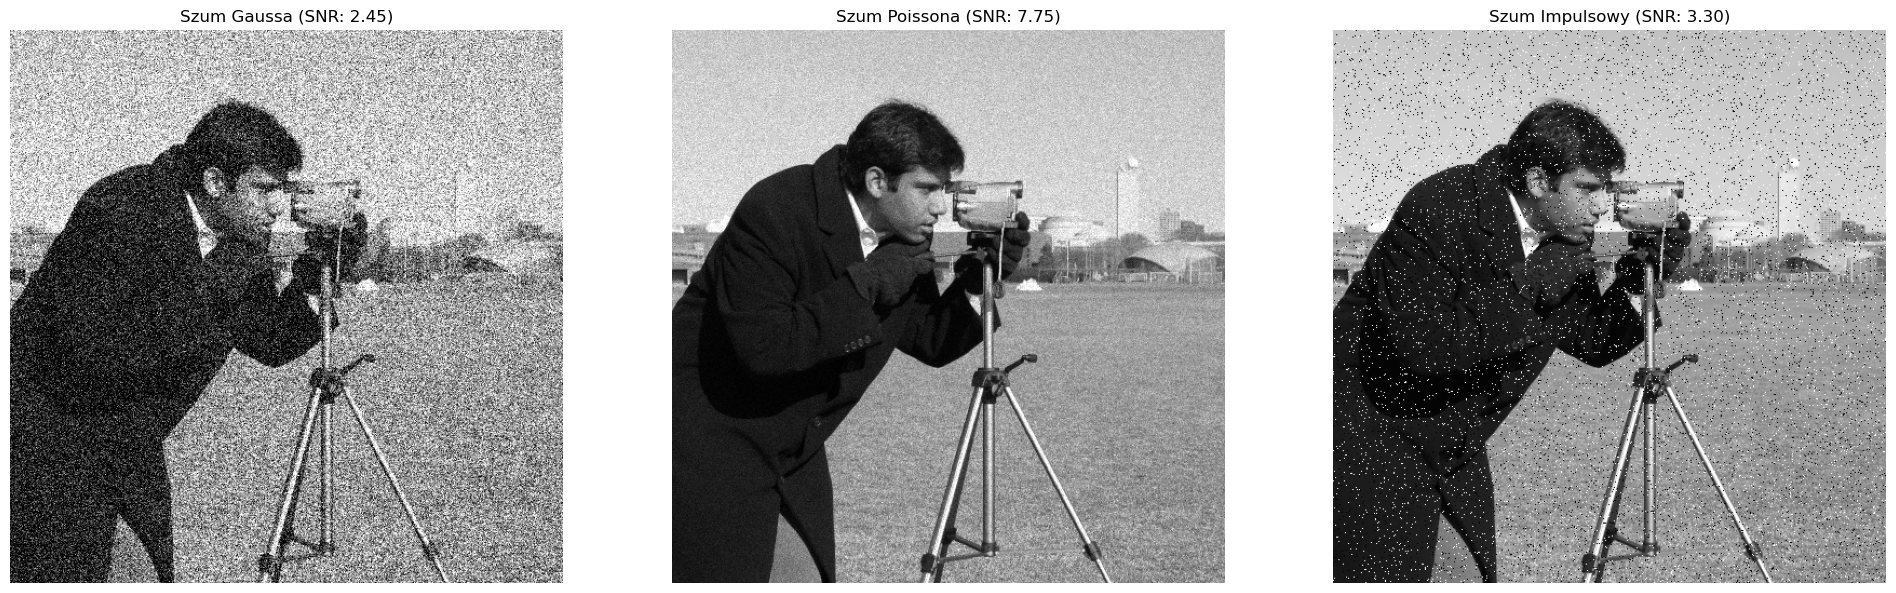

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, util

image = data.camera() / 255.0  # Normalizacja obrazu referencyjnego

# Symulacja różnych rodzajów szumu
noisy_gauss = util.random_noise(image, mode='gaussian', var=0.05)
noisy_poisson = util.random_noise(image, mode='poisson')
noisy_sp = util.random_noise(image, mode='s&p', amount=0.05)

# Funkcja do wyliczania SNR
def calculate_snr(img, roi_signal, roi_noise):
    signal_mean = np.mean(img[roi_signal])
    noise_std = np.std(img[roi_noise])
    return signal_mean / noise_std if noise_std > 0 else 0

# Definiujemy wspołrzędne naszych Regionów Zainteresowania (ROI)
roi_sig = (slice(150, 200), slice(200, 250)) # Jednorodny fragment płaszcza
roi_bg = (slice(0, 50), slice(0, 50))       # Tło (powietrze/niebo)

# Obliczenia SNR
snr_gauss = calculate_snr(noisy_gauss, roi_sig, roi_bg)
snr_poisson = calculate_snr(noisy_poisson, roi_sig, roi_bg)
snr_sp = calculate_snr(noisy_sp, roi_sig, roi_bg)

# Wizualizacja 1x3
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

axes[0].imshow(noisy_gauss, cmap='gray')
axes[0].set_title(f'Szum Gaussa (SNR: {snr_gauss:.2f})')

axes[1].imshow(noisy_poisson, cmap='gray')
axes[1].set_title(f'Szum Poissona (SNR: {snr_poisson:.2f})')

axes[2].imshow(noisy_sp, cmap='gray')
axes[2].set_title(f'Szum Impulsowy (SNR: {snr_sp:.2f})')

for ax in axes: 
    ax.axis('off')
plt.tight_layout()
plt.show()